# Sleep Efficiency Prediction using Linear Regression
Goal: predict **Sleep efficiency** (a continuous value between 0 and 1) from daily habits.

In [1]:
## Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

In [2]:
# Load the sleep efficiency dataset (download from Kaggle and keep it in the data folder)
df = pd.read_csv('Sleep_Efficiency.csv')

In [3]:
df.head()

,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,1,65,Female,2021-03-06 01:00:00,2021-03-06 07:00:00,6.0,0.88,18,70,12,0.0,0.0,0.0,Yes,3.0
1,2,69,Male,2021-12-05 02:00:00,2021-12-05 09:00:00,7.0,0.66,19,28,53,3.0,0.0,3.0,Yes,3.0
2,3,40,Female,2021-05-25 21:30:00,2021-05-25 05:30:00,8.0,0.89,20,70,10,1.0,0.0,0.0,No,3.0
3,4,40,Female,2021-11-03 02:30:00,2021-11-03 08:30:00,6.0,0.51,23,25,52,3.0,50.0,5.0,Yes,1.0
4,5,57,Male,2021-03-13 01:00:00,2021-03-13 09:00:00,8.0,0.76,27,55,18,3.0,0.0,3.0,No,3.0


In [4]:
df.describe()

,ID,Age,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Exercise frequency
count,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,432.000000,427.000000,438.000000,446.000000
mean,226.500000,40.285398,7.465708,0.788916,22.615044,52.823009,24.561947,1.641204,23.653396,1.173516,1.791480
std,130.625419,13.172250,0.866625,0.135237,3.525963,15.654235,15.313665,1.356762,30.202785,1.621377,1.428134
min,1.000000,9.000000,5.000000,0.500000,15.000000,18.000000,7.000000,0.000000,0.000000,0.000000,0.000000
25%,113.750000,29.000000,7.000000,0.697500,20.000000,48.250000,15.000000,1.000000,0.000000,0.000000,0.000000
50%,226.500000,40.000000,7.500000,0.820000,22.000000,58.000000,18.000000,1.000000,25.000000,0.000000,2.000000
75%,339.250000,52.000000,8.000000,0.900000,25.000000,63.000000,32.500000,3.000000,50.000000,2.000000,3.000000
max,452.000000,69.000000,10.000000,0.990000,30.000000,75.000000,63.000000,4.000000,200.000000,5.000000,5.000000


In [5]:
## Check missing values
df.isnull().sum()

,0
ID,0
Age,0
Gender,0
Bedtime,0
Wakeup time,0
Sleep duration,0
Sleep efficiency,0
REM sleep percentage,0
Deep sleep percentage,0
Light sleep percentage,0


In [6]:
## Clean the data
# drop columns we do not need (ID, times) and the sleep stage columns that add up to 100%
df = df.drop(['ID', 'Bedtime', 'Wakeup time', 'REM sleep percentage', 'Light sleep percentage'], axis=1)

# fill missing values with the median
df = df.fillna(df.median(numeric_only=True))

# convert text columns to 0/1
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Smoking status'] = df['Smoking status'].map({'Yes': 1, 'No': 0})

In [7]:
df

,Age,Gender,Sleep duration,Sleep efficiency,Deep sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,65,0,6.0,0.88,70,0.0,0.0,0.0,1,3.0
1,69,1,7.0,0.66,28,3.0,0.0,3.0,1,3.0
2,40,0,8.0,0.89,70,1.0,0.0,0.0,0,3.0
3,40,0,6.0,0.51,25,3.0,50.0,5.0,1,1.0
4,57,1,8.0,0.76,55,3.0,0.0,3.0,0,3.0
...,...,...,...,...,...,...,...,...,...,...
447,27,0,7.5,0.91,57,0.0,0.0,0.0,0,5.0
448,52,1,6.0,0.74,57,4.0,25.0,0.0,0,3.0
449,40,0,8.5,0.55,32,1.0,25.0,3.0,1,0.0
450,45,1,7.0,0.76,72,3.0,0.0,0.0,0,3.0


In [8]:
#Features (independent variables) and target (dependent variable)
X = df.drop('Sleep efficiency', axis=1)
y = df['Sleep efficiency']

In [9]:
X

,Age,Gender,Sleep duration,Deep sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,65,0,6.0,70,0.0,0.0,0.0,1,3.0
1,69,1,7.0,28,3.0,0.0,3.0,1,3.0
2,40,0,8.0,70,1.0,0.0,0.0,0,3.0
3,40,0,6.0,25,3.0,50.0,5.0,1,1.0
4,57,1,8.0,55,3.0,0.0,3.0,0,3.0
...,...,...,...,...,...,...,...,...,...
447,27,0,7.5,57,0.0,0.0,0.0,0,5.0
448,52,1,6.0,57,4.0,25.0,0.0,0,3.0
449,40,0,8.5,32,1.0,25.0,3.0,1,0.0
450,45,1,7.0,72,3.0,0.0,0.0,0,3.0


In [10]:
y

,Sleep efficiency
0,0.88
1,0.66
2,0.89
3,0.51
4,0.76
...,...
447,0.91
448,0.74
449,0.55
450,0.76


In [11]:
## split the dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Simple linear regression (1 feature)

In [12]:
# pick the feature most correlated with the target
best = df.corr()['Sleep efficiency'].drop('Sleep efficiency').abs().idxmax()
print("Best feature:", best)

simple = LinearRegression()
simple.fit(X_train[[best]], y_train)
print("intercept:", simple.intercept_)
print("slope:", simple.coef_[0])
print("R2:", r2_score(y_test, simple.predict(X_test[[best]])))

Best feature: Deep sleep percentage
intercept: 0.42707372746062994
slope: 0.006829769452780476
R2: 0.585313793677752


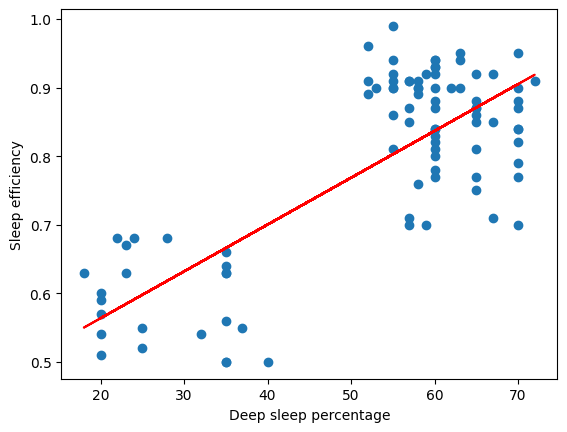

In [13]:
plt.scatter(X_test[best], y_test)
plt.plot(X_test[best], simple.predict(X_test[[best]]), color='red')
plt.xlabel(best)
plt.ylabel('Sleep efficiency')
plt.show()

## Multiple linear regression (all features)

In [14]:
## Train linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [15]:
# make prediction on test set
y_pred = model.predict(X_test)

In [16]:
## Evaluate the model using mean squared error and R2 score
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE:", mse)
print("MAE:", mae)
print("R2:", r2)

MSE: 0.004854027790306135
MAE: 0.05656547353126
R2: 0.7392839872073309


In [17]:
print(f"intercept: {model.intercept_}")
print(f"coefficient: {model.coef_}")

intercept: 0.5051646165800915
coefficient: [ 0.00092315 -0.00115922  0.00361072  0.00534963 -0.0346829   0.00011065
 -0.00652148 -0.03901039  0.00577176]


In [18]:
coef_df = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
coef_df

,Coefficient
Age,0.000923
Gender,-0.001159
Sleep duration,0.003611
Deep sleep percentage,0.005350
Awakenings,-0.034683
Caffeine consumption,0.000111
Alcohol consumption,-0.006521
Smoking status,-0.039010
Exercise frequency,0.005772


## Residuals (actual - predicted)

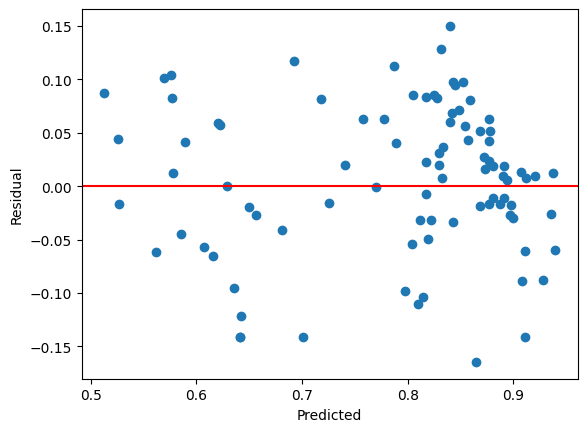

In [19]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.show()

## Least squares by hand (normal equation)
Same answer as sklearn, calculated with NumPy.

In [20]:
A = np.c_[np.ones(len(X_train)), X_train.values]   # add a column of 1s for the intercept
beta = np.linalg.inv(A.T @ A) @ A.T @ y_train.values
print("intercept:", beta[0])
print("coefficients:", beta[1:])

intercept: 0.5051646165800636
coefficients: [ 0.00092315 -0.00115922  0.00361072  0.00534963 -0.0346829   0.00011065
 -0.00652148 -0.03901039  0.00577176]


## Test the model with new data

In [21]:
new_data = pd.DataFrame({
    'Age': [25],
    'Gender': [1],
    'Sleep duration': [7.5],
    'Deep sleep percentage': [60],
    'Awakenings': [1],
    'Caffeine consumption': [25],
    'Alcohol consumption': [0],
    'Smoking status': [0],
    'Exercise frequency': [3]
})

predicted_efficiency = model.predict(new_data[X.columns])
print(predicted_efficiency)

[0.860541]


In [22]:
## Take input from user and predict sleep efficiency
age = float(input("Age: "))
gender = input("Gender (Male/Female): ")
duration = float(input("Sleep duration (hours): "))
deep = float(input("Deep sleep percentage (e.g. 60): "))
awakenings = float(input("Awakenings (number of times): "))
caffeine = float(input("Caffeine consumption (mg, last 24h): "))
alcohol = float(input("Alcohol consumption (oz, last 24h): "))
smoking = input("Smoking status (Yes/No): ")
exercise = float(input("Exercise frequency (times per week): "))

user_data = pd.DataFrame({
    'Age': [age],
    'Gender': [1 if gender.strip().lower() == 'male' else 0],
    'Sleep duration': [duration],
    'Deep sleep percentage': [deep],
    'Awakenings': [awakenings],
    'Caffeine consumption': [caffeine],
    'Alcohol consumption': [alcohol],
    'Smoking status': [1 if smoking.strip().lower() == 'yes' else 0],
    'Exercise frequency': [exercise]
})

prediction = model.predict(user_data[X.columns])[0]
print(f"\nPredicted sleep efficiency: {prediction:.2f} ({prediction*100:.0f}%)")

Age: 18
Gender (Male/Female): male
Sleep duration (hours): 5
Deep sleep percentage (e.g. 60): 40
Awakenings (number of times): 3
Caffeine consumption (mg, last 24h): 20
Alcohol consumption (oz, last 24h): 0
Smoking status (Yes/No): no
Exercise frequency (times per week): 4

Predicted sleep efficiency: 0.67 (67%)
